In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("First 5 Records:")
display(df.head())

print("Last 5 Records:")
display(df.tail())

First 5 Records:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


Last 5 Records:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


In [4]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Number of Rows: 891
Number of Columns: 15

Column Names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object

In [5]:
display(pd.DataFrame({
    "Column Name": df.columns,
    "Data Type": df.dtypes.astype(str).values
}))

,Column Name,Data Type
0,survived,int64
1,pclass,int64
2,sex,object
3,age,float64
4,sibsp,int64
5,parch,int64
6,fare,float64
7,embarked,object
8,class,object
9,who,object


In [6]:
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

Numerical Columns:
['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']

Categorical Columns:
['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


In [7]:
print("Numerical Summary Statistics:")
display(df.describe())


Numerical Summary Statistics:


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
print("Unique Values in Categorical Columns:")

for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))

Unique Values in Categorical Columns:

sex:
sex
male      577
female    314
Name: count, dtype: int64

embarked:
embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64

class:
class
Third     491
First     216
Second    184
Name: count, dtype: int64

who:
who
man      537
woman    271
child     83
Name: count, dtype: int64

adult_male:
adult_male
True     537
False    354
Name: count, dtype: int64

deck:
deck
NaN    688
C       59
B       47
D       33
E       32
A       15
F       13
G        4
Name: count, dtype: int64

embark_town:
embark_town
Southampton    644
Cherbourg      168
Queenstown      77
NaN              2
Name: count, dtype: int64

alive:
alive
no     549
yes    342
Name: count, dtype: int64

alone:
alone
True     537
False    354
Name: count, dtype: int64


Write this observation:

"The dataset contains both numerical and categorical features. The survived column can be used as the target variable for a future classification task. Some columns contain missing values, and certain columns provide redundant information."

In [9]:
missing_count = df.isnull().sum()

missing_percentage = (
    df.isnull().sum() / len(df) * 100
)

missing_report = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percentage.round(2)
})

display(missing_report)

,Missing Values,Missing Percentage
survived,0,0.00
pclass,0,0.00
sex,0,0.00
age,177,19.87
sibsp,0,0.00
parch,0,0.00
fare,0,0.00
embarked,2,0.22
class,0,0.00
who,0,0.00


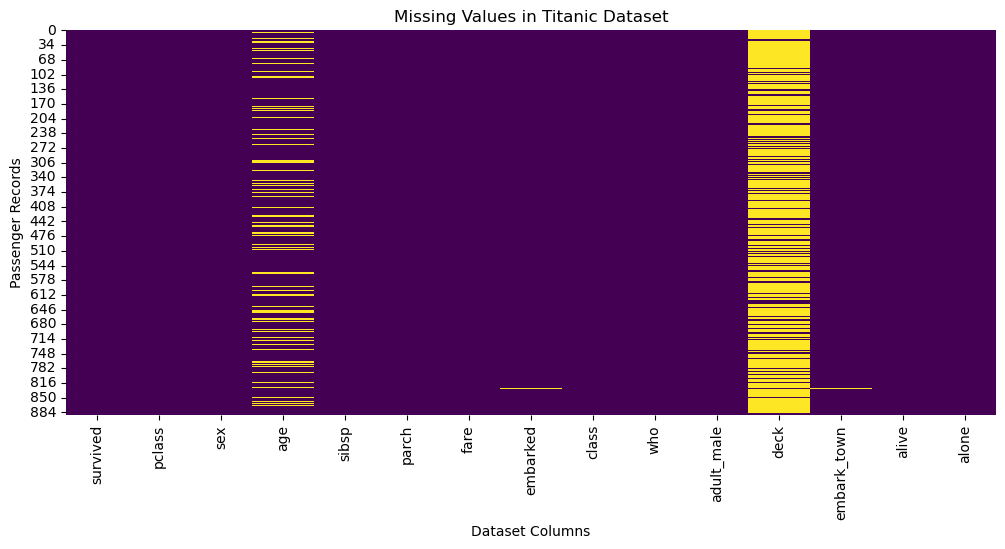

In [10]:
plt.figure(figsize=(12, 5))

sns.heatmap(df.isnull(), cbar=False, cmap="viridis")

plt.title("Missing Values in Titanic Dataset")
plt.xlabel("Dataset Columns")
plt.ylabel("Passenger Records")

plt.show()

The age, deck, embarked, and embark_town columns contain missing values. The deck column has a particularly high percentage of missing data. These missing values need to be handled before further analysis.

In [11]:
df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

Original dataset shape: (891, 15)
Working dataset shape: (891, 15)


In [12]:

df_clean["age"] = df_clean["age"].fillna(
    df_clean["age"].median()
)


df_clean["embarked"] = df_clean["embarked"].fillna(
    df_clean["embarked"].mode()[0]
)


df_clean.drop(columns=["deck"], inplace=True)

print("Missing values handled successfully!")

Missing values handled successfully!


In [13]:
print("Missing Values After Treatment:")
display(df_clean.isnull().sum())

Missing Values After Treatment:


survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    2
alive          0
alone          0
dtype: int64

In [17]:
print("Duplicate Rows Before Cleaning:",
      df_clean.duplicated().sum())

Duplicate Rows Before Cleaning: 0


In [18]:
display(df_clean[df_clean.duplicated(keep=False)].head(10))

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone


In [16]:
df_clean = df_clean.drop_duplicates()

print("Duplicate Rows After Cleaning:",
      df_clean.duplicated().sum())

Duplicate Rows After Cleaning: 0


In [19]:
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip().str.lower()

print("Categorical values standardized.")

Categorical values standardized.


In [20]:
for col in df_clean.select_dtypes(include="object").columns:
    print("\nColumn:", col)
    print(df_clean[col].unique())


Column: sex
['male' 'female']

Column: embarked
['s' 'c' 'q']

Column: class
['third' 'first' 'second']

Column: who
['man' 'woman' 'child']

Column: embark_town
['southampton' 'cherbourg' 'queenstown' nan]

Column: alive
['no' 'yes']


In [21]:
columns_to_remove = [
    "alive",
    "class",
    "who",
    "adult_male",
    "embark_town"
]

df_clean.drop(
    columns=columns_to_remove,
    inplace=True
)

print("Redundant columns removed.")
print("Current Shape:", df_clean.shape)

Redundant columns removed.
Current Shape: (775, 9)


In [22]:

print("Final Numerical Summary:")
display(df_clean.describe())

Final Numerical Summary:


,survived,pclass,age,sibsp,parch,fare
count,775.000000,775.000000,775.000000,775.000000,775.000000,775.000000
mean,0.412903,2.246452,29.581187,0.529032,0.420645,34.878403
std,0.492674,0.853574,13.766359,0.990326,0.840565,52.408474
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,21.000000,0.000000,0.000000,8.050000
50%,0.000000,3.000000,28.000000,0.000000,0.000000,15.900000
75%,1.000000,3.000000,36.000000,1.000000,1.000000,34.197900
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [23]:
print("Passenger Gender Frequency:")
display(df_clean["sex"].value_counts())

Passenger Gender Frequency:


sex
male      483
female    292
Name: count, dtype: int64

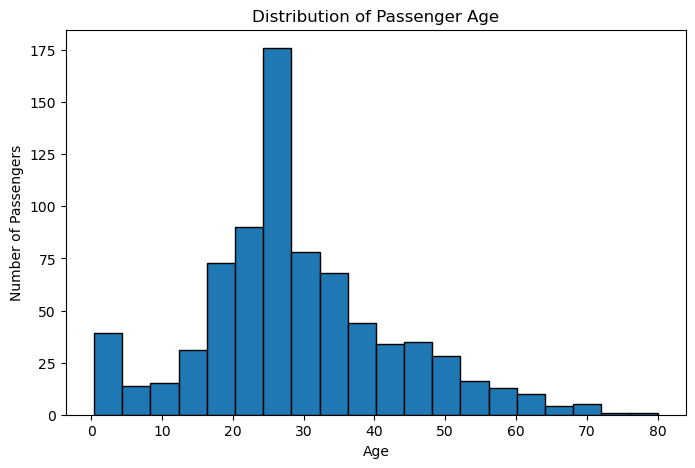

In [24]:
plt.figure(figsize=(8, 5))

plt.hist(df_clean["age"], bins=20, edgecolor="black")

plt.title("Distribution of Passenger Age")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

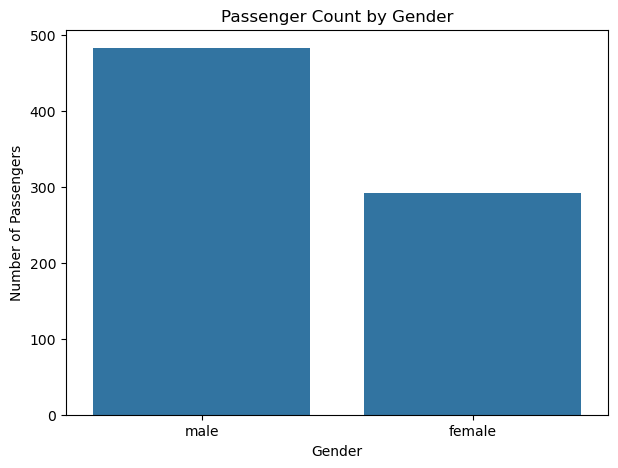

In [25]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x="sex")

plt.title("Passenger Count by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.show()

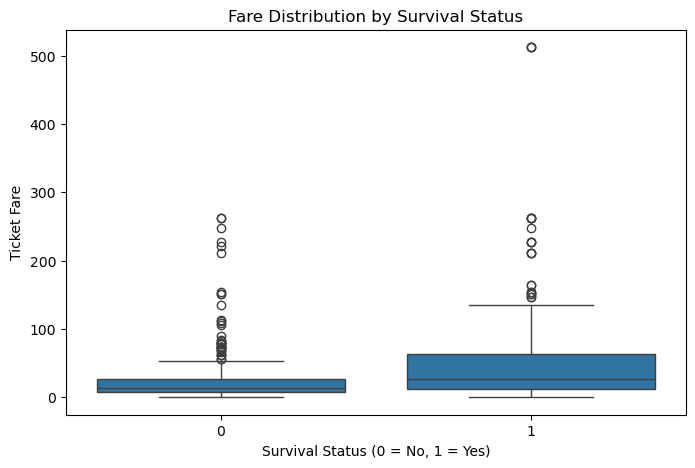

In [26]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean, x="survived", y="fare")

plt.title("Fare Distribution by Survival Status")
plt.xlabel("Survival Status (0 = No, 1 = Yes)")
plt.ylabel("Ticket Fare")

plt.show()

The age histogram shows the distribution of passenger ages and helps identify the most common age groups.



The gender count chart shows the number of male and female passengers.



The fare box plot helps compare ticket fare distributions between passengers who survived and those who did not.

In [27]:
print("Categorical Columns:")
print(df_clean.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist())

Categorical Columns:
['sex', 'embarked', 'alone']


In [28]:
# Convert Boolean column into numeric values
df_clean["alone"] = df_clean["alone"].astype(int)

# One-hot encoding for nominal categorical features
df_clean = pd.get_dummies(
    df_clean,
    columns=["sex", "embarked"],
    dtype=int
)

print("Categorical Encoding Completed!")

display(df_clean.head())


Categorical Encoding Completed!


,survived,pclass,age,sibsp,parch,fare,alone,sex_female,sex_male,embarked_c,embarked_q,embarked_s
0,0,3,22.0,1,0,7.2500,0,0,1,0,0,1
1,1,1,38.0,1,0,71.2833,0,1,0,1,0,0
2,1,3,26.0,0,0,7.9250,1,1,0,0,0,1
3,1,1,35.0,1,0,53.1000,0,1,0,0,0,1
4,0,3,35.0,0,0,8.0500,1,0,1,0,0,1


In [29]:
numerical_features = [
    "pclass",
    "age",
    "sibsp",
    "parch",
    "fare"
]

print("Features selected for scaling:")
print(numerical_features)

Features selected for scaling:
['pclass', 'age', 'sibsp', 'parch', 'fare']


In [30]:
print("Mean After Scaling:")
display(df_clean[numerical_features].mean().round(2))

print("\nStandard Deviation After Scaling:")
display(df_clean[numerical_features].std().round(2))

Mean After Scaling:


pclass     2.25
age       29.58
sibsp      0.53
parch      0.42
fare      34.88
dtype: float64


Standard Deviation After Scaling:


pclass     0.85
age       13.77
sibsp      0.99
parch      0.84
fare      52.41
dtype: float64

In [31]:
print("Final Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

print("\nFinal Column Names:")
print(df_clean.columns.tolist())

Final Dataset Shape: (775, 12)

Missing Values:
0

Duplicate Rows:
0

Final Column Names:
['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare', 'alone', 'sex_female', 'sex_male', 'embarked_c', 'embarked_q', 'embarked_s']


In [32]:
print("First 10 Records of Prepared Dataset:")
display(df_clean.head(10))

First 10 Records of Prepared Dataset:


,survived,pclass,age,sibsp,parch,fare,alone,sex_female,sex_male,embarked_c,embarked_q,embarked_s
0,0,3,22.0,1,0,7.2500,0,0,1,0,0,1
1,1,1,38.0,1,0,71.2833,0,1,0,1,0,0
2,1,3,26.0,0,0,7.9250,1,1,0,0,0,1
3,1,1,35.0,1,0,53.1000,0,1,0,0,0,1
4,0,3,35.0,0,0,8.0500,1,0,1,0,0,1
5,0,3,28.0,0,0,8.4583,1,0,1,0,1,0
6,0,1,54.0,0,0,51.8625,1,0,1,0,0,1
7,0,3,2.0,3,1,21.0750,0,0,1,0,0,1
8,1,3,27.0,0,2,11.1333,0,1,0,0,0,1
9,1,2,14.0,1,0,30.0708,0,1,0,1,0,0


In [33]:
output_file = "Titanic_Prepared_Dataset.csv"

df_clean.to_csv(output_file, index=False)

print("Dataset saved successfully!")
print("File Name:", output_file)

Dataset saved successfully!
File Name: Titanic_Prepared_Dataset.csv


"The Titanic dataset was selected to perform data preparation and exploratory data analysis. The dataset was inspected to understand its structure, data types, and statistical properties. Missing values were handled using median and mode imputation, while the deck column was removed due to excessive missing values. Duplicate records and categorical consistency were checked. Exploratory data analysis was performed using histograms, bar charts, and box plots. Categorical features were encoded using one-hot encoding, and numerical features were standardized using StandardScaler. Finally, the prepared dataset was saved as a separate CSV file. The resulting dataset is ready for further machine learning experimentation, subject to an appropriate train-test split and preprocessing workflow."